In [142]:
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

# -------------------------------------------------
# Load data
# -------------------------------------------------
MIN_TIME_THRESH = 1
MAX_TIME_THRESH = 1800
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)
from IPython.display import display, HTML
pd.options.display.float_format = "{:.1f}".format
def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html(index=False)}
    </div>
    """))
file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="all")
df = df.rename(columns=lambda c: c.replace("-total", ""))
df = clean_dataframe(df)

all_algos=[
    'kPEX-S', 'kPEX-R', 'kPEX-P', 'kPEX-B',
    'UMKP-S', 'UMKP-R', 'UMKP-P',
    'UMKP+-S', 'UMKP+-R', 'UMKP+-P'
]
baseline_algos="UMKP-Imp    UMKP    kPEX-Imp        kPEX    Maple   DiseMKP kPlexT".split()
bnb_cols = [f"{algo}-bnb" for algo in all_algos]
total_cols = [f"{algo}" for algo in all_algos]

remove_rows = (
    (df[bnb_cols] < 1).all(axis=1) |
    (df[bnb_cols] == 1800).all(axis=1)
)
# df = df.loc[~remove_rows].copy()
print(df.shape)

feature_cols = "dataset	k	n	m	d_avg	d_max	core_number	shell_sizes".split()
export_df = df[feature_cols + bnb_cols + total_cols].copy()
export_df = export_df.mask(
    pd.to_numeric(export_df.stack(), errors="coerce").unstack() == 1800,
    "x"
)
export_df.to_csv("ml-data.csv", index=False)
# display(filtered_df[feature_cols + bnb_cols+total_cols])



(4356, 99)


/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_62339/112625365.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_62339/112625365.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_62339/112625365.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain 

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_62339/1695757801.py:27: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_work = df_work[~(vals >= max_time_thresh).all(axis=1)]


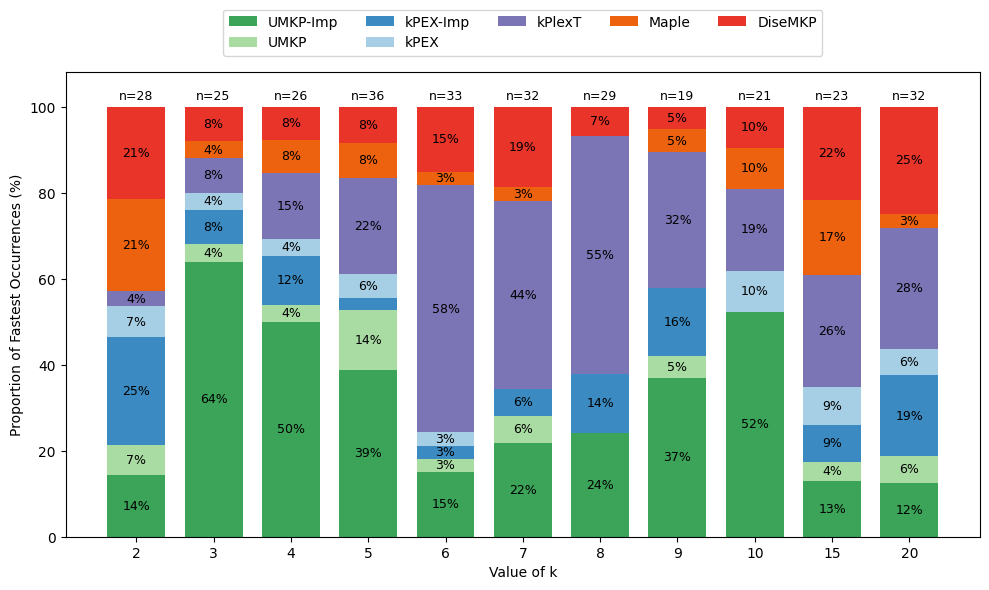

In [157]:
def plot_fastest_occurrences(
    df,
    suffix="",
    groups=None,
    k_values=None,
    min_time_thresh=1,
    max_time_thresh=1800,
    min_abs_gap=10,
    figsize=(10, 6),
    annotate_thresh=3,
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    groups = ["UMKP-Imp UMKP".split(), "kPEX-Imp kPEX".split(), ["kPlexT"], ["Maple"], ["DiseMKP"]]
    if k_values is None:
        k_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20]

    all_algos = sum(groups, [])
    cols = [f"{algo}-{suffix}" if suffix else algo for algo in all_algos]

    df_work = df.copy()
    vals = df_work[cols].apply(pd.to_numeric, errors="coerce")

    df_work = df_work[~(vals < min_time_thresh).all(axis=1)]
    df_work = df_work[~(vals >= max_time_thresh).all(axis=1)]
    vals = df_work[cols].apply(pd.to_numeric, errors="coerce")

    second_best = vals.apply(
        lambda row: row.nsmallest(2).iloc[-1] if row.notna().sum() >= 2 else np.nan,
        axis=1
    )
    best = vals.min(axis=1)

    keep_mask = (second_best - best) >= min_abs_gap
    df_work = df_work[keep_mask].copy()
    vals = vals.loc[keep_mask].copy()

    results = {col: [] for col in cols}
    counts_per_k = []

    for k in k_values:
        mask = df_work["k"] == k
        vals_k = vals.loc[mask]
        counts_per_k.append(len(vals_k))

        if len(vals_k) == 0:
            for col in cols:
                results[col].append(0)
            continue

        winners = vals_k.idxmin(axis=1)
        win_counts = winners.value_counts()
        total = len(vals_k)

        for col in cols:
            results[col].append((win_counts.get(col, 0) / total) * 100)

    res_df = pd.DataFrame(results, index=k_values)

    cmaps = [
        plt.cm.Greens,
        plt.cm.Blues,
        plt.cm.Purples,
        plt.cm.Oranges,
        plt.cm.Reds,
        plt.cm.Greys,
        plt.cm.YlGnBu,
    ]

    colors = {}
    for group, cmap in zip(groups, cmaps):
        shades = cmap(np.linspace(0.65, 0.35, len(group)))
        for algo, shade in zip(group, shades):
            key = f"{algo}-{suffix}" if suffix else algo
            colors[key] = shade

    x = np.arange(len(k_values))
    fig, ax = plt.subplots(figsize=figsize)
    bottom = np.zeros(len(k_values))

    for col in cols:
        vals_col = res_df[col].values

        ax.bar(
            x,
            vals_col,
            bottom=bottom,
            label=col,
            width=0.75,
            color=colors[col]
        )

        for i, v in enumerate(vals_col):
            if v > annotate_thresh:
                ax.text(
                    x[i],
                    bottom[i] + v / 2,
                    f"{v:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="black"
                )

        bottom += vals_col

    for i, cnt in enumerate(counts_per_k):
        ax.text(
            x[i],
            101,
            f"n={cnt}",
            ha="center",
            va="bottom",
            fontsize=9,
            color="black"
        )

    ax.set_xlabel("Value of k")
    ax.set_ylabel("Proportion of Fastest Occurrences (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(k_values)
    ax.set_ylim(0, 108)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=5)

    plt.tight_layout()
    return res_df, fig, ax
res_df, fig, ax = plot_fastest_occurrences(df, suffix="")


=== Threshold 1.2 Analysis ===
Ignoring rows with |kPEX-B - kPEX-Imp| < 10
kPEX-B wins: 228
kPEX-Imp wins: 301
Sorting by: speedup

--- Weaker side: kPEX-B ---


dataset,k,kPEX-B,kPEX-Imp,abs_diff,speedup
soc-bitcoin,4,5.7,1800.0,1794.3,313.25x
nd12k,4,6.3,1800.0,1793.7,284.96x
soc-bitcoin,5,6.8,1800.0,1793.2,262.89x
sx-stackoverflow,5,7.8,1800.0,1792.2,229.76x
nd24k,5,8.1,1800.0,1791.9,221.35x
san200-0-9-2,4,5.3,987.1,981.8,184.72x
soc-bitcoin,2,6.8,1225.0,1218.2,180.23x
nd24k,4,10.2,1800.0,1789.8,177.28x
edit-eswiki,5,1.8,284.2,282.3,153.85x
sx-stackoverflow,3,12.5,1800.0,1787.5,144.15x



--- Stronger side: kPEX-Imp ---


dataset,k,kPEX-B,kPEX-Imp,abs_diff,speedup
Maragal_7,5,1800.0,0.4,1799.6,5033.56x
reactome,4,1800.0,0.9,1799.1,1974.33x
slptsk,4,58.9,0.1,58.8,789.58x
TSC_OPF_300,5,1333.2,2.1,1331.1,627.58x
Maragal_5,5,1800.0,3.8,1796.2,468.62x
orani678,4,1800.0,6.0,1794.0,299.82x
cit-Patents,5,101.0,0.4,100.6,235.04x
cit-Patents,3,128.4,0.7,127.7,185.29x
cit-Patents,4,89.2,0.5,88.7,180.93x
Maragal_6,5,160.6,1.1,159.5,140.85x


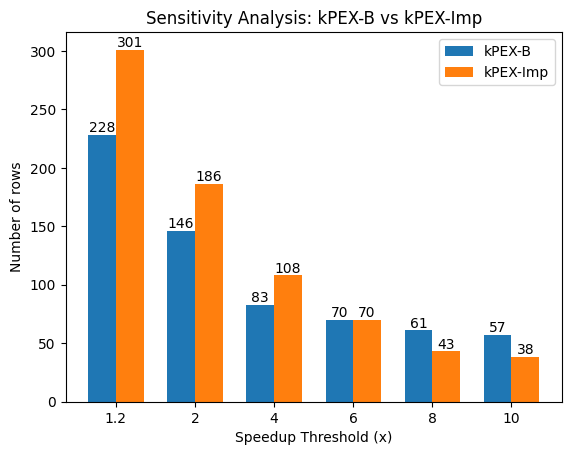

In [160]:
def compare_speedups(df, col_a, col_b,
                     thresholds=[1.2, 2, 4, 6, 8, 10],
                     min_time_threshold=1.0,
                     min_abs_diff=10.0,
                     max_len=25,
                     sort_by="speedup"):
    
    import matplotlib.pyplot as plt

    va = col_a.split("-")[0]
    vb = col_b.split("-")[0]

    df = df.replace(0, 0.01)

    df_filtered = df[
        ((df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)) &
        ((df[col_a] - df[col_b]).abs() >= min_abs_diff)
    ].copy()

    df_filtered["abs_diff"] = (df_filtered[col_a] - df_filtered[col_b]).abs()
    df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
    df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

    def sort_df(df_in, side):
        if sort_by == "speedup":
            key = "speedup_a" if side == "A" else "speedup_b"
        elif sort_by == "runtime":
            key = col_a if side == "A" else col_b
        elif sort_by == "abs_diff":
            key = "abs_diff"
        else:
            raise ValueError("sort_by must be 'speedup', 'runtime', or 'abs_diff'")
        return df_in.sort_values(by=key, ascending=False)

    threshold_check = thresholds[0]

    a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
    b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

    if len(a_wins) < len(b_wins):
        weaker, stronger = "A", "B"
    elif len(b_wins) < len(a_wins):
        weaker, stronger = "B", "A"
    else:
        weaker = stronger = "Tie"

    def format_df(df_in, side):
        if side == "A":
            speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        else:
            speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")

        return df_in.assign(
            dataset=df_in["dataset"].apply(
                lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
            ),
            speedup=speedup_series
        )[[
            "dataset", "k",
            col_a, col_b,
            "abs_diff",
            "speedup"
        ]]

    print(f"\n=== Threshold {threshold_check} Analysis ===")
    print(f"Ignoring rows with |{col_a} - {col_b}| < {min_abs_diff}")
    print(f"{col_a} wins: {len(a_wins)}")
    print(f"{col_b} wins: {len(b_wins)}")
    print(f"Sorting by: {sort_by}")

    if weaker == "Tie":
        print("Both sides have equal wins.")

        print("\n--- Side A (>= threshold) ---")
        display_scroll(format_df(sort_df(a_wins, "A"), "A"))

        print("\n--- Side B (>= threshold) ---")
        display_scroll(format_df(sort_df(b_wins, "B"), "B"))

    else:
        if weaker == "A":
            weaker_df = sort_df(a_wins, "A")
            stronger_df = sort_df(b_wins, "B")
            weaker_name, stronger_name = col_a, col_b

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "A"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "B"))

        else:
            weaker_df = sort_df(b_wins, "B")
            stronger_df = sort_df(a_wins, "A")
            weaker_name, stronger_name = col_b, col_a

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "B"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "A"))

    a_counts = [(df_filtered["speedup_a"] >= t).sum() for t in thresholds]
    b_counts = [(df_filtered["speedup_b"] >= t).sum() for t in thresholds]

    x = range(len(thresholds))
    width = 0.35

    plt.figure()

    bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
    bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{int(height)}",
                ha='center',
                va='bottom'
            )

    add_labels(bars_a)
    add_labels(bars_b)

    plt.xticks(x, thresholds)
    plt.xlabel("Speedup Threshold (x)")
    plt.ylabel("Number of rows")
    plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")
    plt.legend()
    plt.show()

compare_speedups(df, "kPEX-B", "kPEX-Imp", min_abs_diff=10)

In [88]:
k_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20]
best_by_k = {}

for k in k_values:
    filtered_df = df[df["k"] == k].copy()
    algo_vals = filtered_df[all_algos].apply(pd.to_numeric, errors="coerce")

    filtered_df["best_algo"] = algo_vals.idxmin(axis=1)
    filtered_df["best_time"] = algo_vals.min(axis=1)
    filtered_df["second_best_time"] = algo_vals.apply(
        lambda row: row.nsmallest(2).iloc[-1] if row.notna().sum() >= 2 else pd.NA,
        axis=1,
    )
    filtered_df["best_to_second_ratio"] = filtered_df["second_best_time"] / filtered_df["best_time"]
    filtered_df = filtered_df.sort_values("best_to_second_ratio", ascending=False)
    best_by_k[k] = filtered_df

    print(f"Rows for k = {k} {filtered_df.shape}")
    display_scroll(filtered_df[["dataset", "k", "best_algo", "best_time", "second_best_time", "best_to_second_ratio"] + all_algos])


Rows for k = 2 (184, 102)


,dataset,k,best_algo,best_time,second_best_time,best_to_second_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
2834,reactome,2,kPEX-R,0.2,117.7,479.4,117.7,0.2,1800.0,1800.0,1800.0,1800.0,1800.0,500.8,1747.5,1800.0
1851,keller4,2,kPEX-S,6.3,26.0,4.1,6.3,27.4,51.8,63.4,26.0,71.1,116.3,29.7,83.6,223.6
1093,edit-nlwiki,2,kPEX-S,405.0,905.3,2.2,405.0,905.3,1426.6,1000.1,1800.0,1800.0,1800.0,1800.0,1800.0,1800.0
1355,flickr-links,2,kPEX-S,45.0,98.4,2.2,45.0,245.0,121.5,98.4,214.7,521.5,1317.4,211.3,541.3,1589.6
3584,soc-themarker,2,kPEX-S,130.2,259.7,2.0,130.2,259.7,597.9,387.8,861.5,1800.0,1800.0,875.0,1800.0,1800.0
1053,edit-eswiki,2,kPEX-S,2.6,4.9,1.9,2.6,5.3,5.8,4.9,8.9,19.7,50.3,9.2,24.5,73.7
1834,johnson8-4-4,2,kPEX-S,0.4,0.7,1.9,0.4,0.8,1.1,1.2,0.7,1.3,1.4,1.0,1.8,3.2
982,discogs_lstyle,2,kPEX-S,0.4,0.7,1.8,0.4,1.0,1.0,0.7,0.8,1.8,2.4,0.7,1.8,3.5
1110,edit-ptwiki,2,kPEX-S,368.7,661.4,1.8,368.7,661.4,1800.0,1546.2,1500.8,1800.0,1800.0,1433.5,1800.0,1800.0
3844,Trec13,2,kPEX-S,257.7,439.3,1.7,257.7,439.3,1800.0,1800.0,1800.0,1800.0,1800.0,1800.0,1800.0,1800.0


Rows for k = 3 (198, 102)


,dataset,k,best_algo,best_time,second_best_time,best_to_second_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
2835,reactome,3,kPEX-R,0.4,14.2,32.0,14.2,0.4,1800.0,1800.0,27.7,1800.0,1800.0,154.0,74.6,1800.0
1852,keller4,3,kPEX-S,5.0,30.7,6.1,5.0,52.9,133.6,72.9,30.7,267.6,350.1,33.6,247.7,616.9
3845,Trec13,3,kPEX-S,332.4,1368.0,4.1,332.4,1368.0,1800.0,1800.0,1419.1,1800.0,1800.0,1404.3,1800.0,1800.0
2552,p-hat700-1,3,kPEX-S,27.8,82.2,3.0,27.8,82.2,347.7,201.6,191.1,1324.9,1136.5,197.8,1307.9,1800.0
568,brock200-2,3,kPEX-S,4.3,10.7,2.5,4.3,10.7,14.9,11.0,20.4,61.6,58.3,20.6,58.6,94.7
1835,johnson8-4-4,3,kPEX-S,2.5,5.5,2.3,2.5,11.7,7.3,6.4,5.5,24.1,14.1,7.0,20.8,22.4
2706,psmigr_1,3,UMKP-P,280.8,585.8,2.1,1800.0,1800.0,585.8,609.4,1800.0,1587.2,280.8,1800.0,1800.0,1800.0
4304,wiki_talk_en,3,kPEX-B,765.7,1586.3,2.1,1800.0,1800.0,1586.3,765.7,1800.0,1800.0,1800.0,1800.0,1800.0,1800.0
2542,p-hat500-1,3,kPEX-S,5.6,11.5,2.1,5.6,11.5,27.7,18.6,22.0,85.4,73.3,21.6,84.3,128.2
3867,TSC_OPF_1047,3,kPEX-S,27.4,55.6,2.0,27.4,1800.0,1800.0,1800.0,55.6,1800.0,1800.0,56.9,1800.0,1800.0


Rows for k = 4 (221, 102)


,dataset,k,best_algo,best_time,second_best_time,best_to_second_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
3846,Trec13,4,kPEX-S,235.1,1066.8,4.5,235.1,1800.0,1800.0,1800.0,1241.0,1800.0,1800.0,1066.8,1800.0,1800.0
1853,keller4,4,kPEX-S,632.5,1750.1,2.8,632.5,1800.0,1800.0,1800.0,1750.1,1800.0,1800.0,1800.0,1800.0,1800.0
2553,p-hat700-1,4,kPEX-S,239.8,599.6,2.5,239.8,736.5,897.4,599.6,651.1,1800.0,1800.0,622.1,1800.0,1800.0
2543,p-hat500-1,4,kPEX-S,21.7,44.4,2.0,21.7,57.9,59.1,44.4,58.4,188.4,151.7,55.5,177.1,246.8
3868,TSC_OPF_1047,4,kPEX-S,27.9,54.9,2.0,27.9,1800.0,1800.0,1800.0,54.9,1800.0,1800.0,56.4,1800.0,1800.0
1876,lastfm_band,4,kPEX-B,54.8,102.5,1.9,1800.0,1800.0,102.5,54.8,148.8,310.1,229.1,157.2,518.7,571.8
2459,orani678,4,UMKP-S,1.8,3.4,1.8,3.4,3.8,1800.0,1800.0,1.8,632.1,1800.0,7.3,132.7,1800.0
3561,soc-sinaweibo,4,UMKP+-S,127.1,214.8,1.7,1100.6,1800.0,339.3,277.2,214.8,341.9,633.4,127.1,909.0,1397.2
2707,psmigr_1,4,kPEX-B,194.8,318.7,1.6,1800.0,1800.0,347.7,194.8,1800.0,1800.0,318.7,1800.0,1800.0,1800.0
2729,psmigr_3,4,kPEX-B,200.6,318.3,1.6,1800.0,1800.0,346.8,200.6,1800.0,1800.0,318.3,1800.0,1800.0,1800.0


... (12 outputs left out)

Rows for k = 15 (375, 102)


,dataset,k,best_algo,best_time,second_best_time,best_to_second_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
1953,link-dynamic-frwiki,15,UMKP+-S,6.2,27.9,4.5,27.9,1800.0,1800.0,1800.0,96.5,1800.0,1800.0,6.2,1800.0,1800.0
2820,ramage02,15,UMKP+-R,42.0,189.3,4.5,244.1,1800.0,601.2,1800.0,504.5,1800.0,761.7,189.3,42.0,240.3
3808,trackers,15,kPEX-R,219.0,741.9,3.4,1056.4,219.0,1782.6,1631.6,1800.0,1286.3,1800.0,1800.0,741.9,1800.0
3886,TSC_OPF_300,15,kPEX-S,2.9,7.6,2.6,2.9,1800.0,1800.0,1800.0,7.6,1800.0,1800.0,10.8,61.6,1800.0
2158,mono_500Hz,15,kPEX-S,6.5,16.9,2.6,6.5,46.7,16.9,16.9,29.4,1328.6,26.8,21.6,103.4,32.7
2066,Maragal_6,15,kPEX-B,41.1,92.3,2.2,1800.0,1800.0,92.3,41.1,1800.0,1800.0,1800.0,1709.1,1800.0,368.7
759,connectus,15,kPEX-R,2.2,4.9,2.2,7.7,2.2,7.3,7.9,1800.0,28.6,8.5,51.0,4.9,10.7
4168,web-wikipedia_link_de,15,UMKP-P,35.0,62.6,1.8,687.8,234.7,288.2,214.8,62.6,110.1,35.0,1678.3,1800.0,1750.3
40,3Dspectralwave2,15,UMKP-P,67.5,106.2,1.6,281.8,118.1,158.5,147.5,1800.0,111.9,67.5,1146.3,106.2,256.2
1709,ia-infect-hyper,15,UMKP-P,0.0,0.0,1.5,0.6,3.2,0.0,0.0,0.3,0.4,0.0,0.0,0.1,0.0


Rows for k = 20 (393, 102)


,dataset,k,best_algo,best_time,second_best_time,best_to_second_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
1687,hood,20,kPEX-B,1.4,4.3,3.0,4.3,47.8,10.2,1.4,36.5,186.7,99.8,15.1,102.5,31.3
1867,kron_g500-logn20,20,kPEX-B,629.9,1800.0,2.9,1800.0,1800.0,1800.0,629.9,1800.0,1800.0,1800.0,1800.0,1800.0,1800.0
2067,Maragal_6,20,kPEX-S,52.3,118.2,2.3,52.3,118.2,1800.0,1800.0,1800.0,1800.0,1800.0,1165.2,1127.4,1800.0
2159,mono_500Hz,20,kPEX-S,19.4,41.6,2.1,19.4,95.0,41.6,55.6,121.2,1800.0,57.6,67.7,222.2,101.7
1315,fcondp2,20,kPEX-R,97.3,208.0,2.1,1800.0,97.3,354.0,208.0,1800.0,1800.0,1800.0,1800.0,1051.6,1387.0
760,connectus,20,kPEX-R,34.8,74.2,2.1,1800.0,34.8,250.0,239.3,1800.0,1800.0,77.6,1800.0,74.2,294.2
443,bcsstk39,20,kPEX-R,1.4,2.9,2.1,26.4,1.4,6.3,2.9,1800.0,1800.0,1409.5,1753.0,38.6,260.2
4313,wiki_talk_en,20,UMKP-P,737.6,1477.9,2.0,1800.0,1800.0,1593.4,1477.9,1800.0,1800.0,737.6,1800.0,1800.0,1800.0
3276,socfb-Duke14,20,UMKP-P,0.9,1.7,1.9,1800.0,1800.0,2.3,2.5,1800.0,1800.0,0.9,1800.0,367.1,1.7
161,aff-github-user2project,20,UMKP-P,254.4,432.9,1.7,1800.0,1800.0,461.0,465.0,1800.0,432.9,254.4,1800.0,447.2,642.0


In [89]:
k_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20]
best_worst_by_k = {}

for k in k_values:
    filtered_df = df[df["k"] == k].copy()
    algo_vals = filtered_df[all_algos].apply(pd.to_numeric, errors="coerce")

    filtered_df["best_algo"] = algo_vals.idxmin(axis=1)
    filtered_df["best_time"] = algo_vals.min(axis=1)
    filtered_df["worst_algo"] = algo_vals.idxmax(axis=1)
    filtered_df["worst_time"] = algo_vals.max(axis=1)
    filtered_df["best_to_worst_ratio"] = filtered_df["worst_time"] / filtered_df["best_time"]
    filtered_df = filtered_df.sort_values("best_to_worst_ratio", ascending=False)
    best_worst_by_k[k] = filtered_df

    print(f"Rows for k = {k} {filtered_df.shape}")
    display_scroll(filtered_df[["dataset", "k", "best_algo", "best_time", "worst_algo", "worst_time", "best_to_worst_ratio"] + all_algos])


Rows for k = 2 (184, 103)


,dataset,k,best_algo,best_time,worst_algo,worst_time,best_to_worst_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
2834,reactome,2,kPEX-R,0.2,kPEX-P,1800.0,7332.0,117.7,0.2,1800.0,1800.0,1800.0,1800.0,1800.0,500.8,1747.5,1800.0
3169,soc-bitcoin,2,UMKP-P,3.5,kPEX-S,1103.8,319.7,1103.8,110.9,4.4,6.8,22.2,28.1,3.5,8.4,57.7,10.6
307,av41092,2,UMKP-R,0.4,UMKP-P,89.7,213.8,0.5,0.4,17.3,13.3,1.3,0.4,89.7,1.3,0.6,60.4
2954,san200-0-9-1,2,kPEX-P,8.9,UMKP-S,1800.0,203.0,383.9,749.6,8.9,95.8,1800.0,88.9,1800.0,13.3,186.9,134.8
2269,nd12k,2,kPEX-P,17.0,kPEX-R,1800.0,105.9,1359.5,1800.0,17.0,24.1,52.3,86.3,21.3,62.3,267.4,70.3
710,cit-Patents,2,kPEX-R,0.2,UMKP+-P,15.0,83.2,0.3,0.2,4.2,7.8,0.6,0.2,10.4,0.6,0.4,15.0
3653,sx-stackoverflow,2,kPEX-B,21.8,kPEX-R,1800.0,82.6,445.8,1800.0,23.6,21.8,49.6,209.6,138.6,47.9,619.5,266.2
1153,edit-viwiki,2,kPEX-S,10.0,UMKP+-P,750.1,75.2,10.0,10.1,36.4,22.5,50.8,86.1,651.4,64.0,34.5,750.1
2280,nd24k,2,kPEX-P,25.7,kPEX-R,1800.0,70.2,1519.0,1800.0,25.7,29.1,42.5,74.7,32.9,45.7,166.7,75.9
1977,lkml-reply,2,kPEX-B,0.3,kPEX-R,20.4,66.3,3.5,20.4,0.4,0.3,0.5,1.8,0.7,0.5,3.4,1.4


Rows for k = 3 (198, 103)


,dataset,k,best_algo,best_time,worst_algo,worst_time,best_to_worst_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
2835,reactome,3,kPEX-R,0.4,kPEX-P,1800.0,4067.8,14.2,0.4,1800.0,1800.0,27.7,1800.0,1800.0,154.0,74.6,1800.0
2458,orani678,3,UMKP-S,1.2,UMKP+-P,1800.0,1526.5,2.6,2.1,522.6,457.4,1.2,131.0,392.7,2.7,3.8,1800.0
711,cit-Patents,3,kPEX-S,0.3,UMKP+-P,200.4,671.4,0.3,3.2,64.0,128.4,0.6,8.2,106.5,0.7,11.8,200.4
2489,patentcite,3,kPEX-S,1.1,UMKP+-P,231.6,218.8,1.1,7.4,67.5,121.0,1.6,18.2,130.4,1.7,24.3,231.6
3654,sx-stackoverflow,3,UMKP-P,11.4,kPEX-S,1800.0,157.9,1800.0,1800.0,12.1,12.5,16.5,20.2,11.4,21.2,55.2,19.6
2270,nd12k,3,UMKP-P,12.5,kPEX-S,1800.0,143.7,1800.0,1800.0,13.9,13.5,68.1,41.8,12.5,86.9,129.7,38.3
2281,nd24k,3,UMKP-P,13.8,kPEX-S,1800.0,130.5,1800.0,1800.0,14.0,15.6,26.6,23.8,13.8,32.5,54.7,23.9
1852,keller4,3,kPEX-S,5.0,UMKP+-P,616.9,123.0,5.0,52.9,133.6,72.9,30.7,267.6,350.1,33.6,247.7,616.9
2069,Maragal_7,3,kPEX-S,0.6,UMKP-P,52.5,93.8,0.6,1.7,16.3,12.5,0.6,0.9,52.5,0.6,0.9,34.3
3170,soc-bitcoin,3,UMKP-P,24.7,kPEX-S,1800.0,73.0,1800.0,1800.0,25.2,136.1,1800.0,559.4,24.7,652.0,1800.0,154.6


Rows for k = 4 (221, 103)


,dataset,k,best_algo,best_time,worst_algo,worst_time,best_to_worst_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
3124,slptsk,4,kPEX-S,0.1,UMKP+-P,190.2,3019.8,0.1,0.1,63.2,58.9,0.1,5.8,42.1,0.1,0.1,190.2
2836,reactome,4,UMKP-S,0.7,kPEX-P,1800.0,2597.4,0.8,28.7,1800.0,1800.0,0.7,131.4,1800.0,1.6,68.2,1800.0
712,cit-Patents,4,kPEX-S,0.3,UMKP+-P,279.3,1041.0,0.3,3.7,74.9,89.2,0.4,13.2,169.3,0.5,9.5,279.3
2459,orani678,4,UMKP-S,1.8,kPEX-P,1800.0,984.5,3.4,3.8,1800.0,1800.0,1.8,632.1,1800.0,7.3,132.7,1800.0
3171,soc-bitcoin,4,UMKP-P,5.2,kPEX-S,1800.0,344.3,1800.0,1800.0,5.5,5.7,836.4,134.8,5.2,76.0,662.8,19.1
2271,nd12k,4,kPEX-P,5.6,kPEX-R,1800.0,320.4,1036.0,1800.0,5.6,6.3,59.6,20.7,5.8,53.3,48.0,10.6
3879,TSC_OPF_300,4,kPEX-S,1.4,UMKP+-P,440.7,309.4,1.4,59.5,217.3,195.9,1.6,7.3,106.4,1.8,7.9,440.7
2070,Maragal_7,4,kPEX-S,0.4,UMKP-P,100.0,262.3,0.4,0.6,18.9,20.8,0.4,0.4,100.0,0.4,0.4,64.3
3655,sx-stackoverflow,4,kPEX-P,7.1,kPEX-R,1800.0,251.8,320.5,1800.0,7.1,9.0,8.0,8.7,7.3,8.2,13.0,7.8
2490,patentcite,4,kPEX-S,0.9,UMKP+-P,195.4,224.2,0.9,3.7,43.9,55.3,1.0,12.4,101.6,1.1,11.2,195.4


... (12 outputs left out)

Rows for k = 15 (375, 103)


,dataset,k,best_algo,best_time,worst_algo,worst_time,best_to_worst_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
3730,tech-WHOIS,15,kPEX-P,0.0,UMKP-R,1800.0,39473.7,1.3,7.3,0.0,0.0,5.0,1800.0,0.1,3.4,0.8,0.1
1290,f855_mat9_I,15,kPEX-S,0.2,UMKP+-P,1800.0,7985.8,0.2,0.4,696.9,1382.4,0.3,1001.1,603.7,0.3,0.8,1800.0
741,com-youtube,15,UMKP-P,0.3,UMKP-S,1800.0,6896.6,54.6,17.0,0.3,0.3,1800.0,1.9,0.3,96.7,2.1,0.4
1984,lkml-reply,15,UMKP-P,0.2,UMKP-R,991.0,6017.1,69.6,878.4,0.2,0.2,143.9,991.0,0.2,9.6,1.3,0.2
3723,tech-as-skitter,15,UMKP+-P,0.4,UMKP-R,1800.0,5138.5,1.1,1.8,0.4,0.4,1.7,1800.0,0.4,0.7,0.6,0.4
3245,socfb-BC17,15,UMKP-P,0.4,kPEX-R,1800.0,4862.2,448.4,1800.0,0.4,0.4,1800.0,960.2,0.4,114.9,45.8,0.6
4327,youtube-links,15,UMKP-P,0.3,UMKP-S,1274.5,4743.3,17.0,2.8,0.3,0.3,1274.5,0.8,0.3,11.3,0.8,0.4
2862,Reuters911,15,UMKP-P,0.5,kPEX-S,1800.0,3872.6,1800.0,1800.0,0.5,0.5,1800.0,146.4,0.5,1800.0,181.7,1.1
1749,ia-wiki-trust-dir,15,UMKP-P,0.2,UMKP-S,540.1,3514.3,9.0,43.8,0.2,0.2,540.1,16.0,0.2,20.8,2.0,0.2
2140,misc-Reuters911,15,UMKP-P,0.5,kPEX-S,1800.0,3469.5,1800.0,1800.0,0.5,0.5,1800.0,148.5,0.5,1800.0,181.9,1.1


Rows for k = 20 (393, 103)


,dataset,k,best_algo,best_time,worst_algo,worst_time,best_to_worst_ratio,kPEX-S,kPEX-R,kPEX-P,kPEX-B,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P
2445,opsahl-usairport,20,UMKP-P,0.0,UMKP-R,1524.4,272207.1,0.0,0.0,0.0,0.0,0.0,1524.4,0.0,0.0,0.0,0.0
3731,tech-WHOIS,20,kPEX-P,0.0,UMKP-R,1800.0,72289.2,0.0,0.1,0.0,0.0,0.1,1800.0,0.0,0.1,0.1,0.0
607,CAG_mat364,20,kPEX-P,0.0,UMKP-R,326.0,49399.3,0.0,0.0,0.0,0.0,0.0,326.0,0.0,0.0,0.0,0.0
455,beacxc,20,UMKP-P,0.0,UMKP-R,1358.2,31294.7,0.1,0.2,0.0,0.1,0.1,1358.2,0.0,0.1,0.1,0.1
2118,memplus,20,UMKP-P,0.0,UMKP-R,433.5,29487.0,0.0,0.0,0.0,0.0,0.0,433.5,0.0,0.0,0.0,0.0
464,beaflw,20,kPEX-P,0.1,UMKP-R,1481.3,26594.0,0.1,0.1,0.1,0.1,0.1,1481.3,0.1,0.1,0.2,0.1
3423,socfb-Wake73,20,kPEX-S,0.1,UMKP-R,1800.0,12203.4,0.1,0.2,0.2,0.2,0.2,1800.0,0.2,0.2,0.2,0.1
2105,mbeaflw,20,UMKP-P,0.0,UMKP-R,420.1,10074.0,0.0,0.2,0.0,0.1,0.1,420.1,0.0,0.1,0.1,0.1
2098,mbeacxc,20,kPEX-P,0.0,UMKP-R,424.4,9987.0,0.0,0.2,0.0,0.0,0.1,424.4,0.0,0.1,0.1,0.1
3373,socfb-Tufts18,20,kPEX-P,0.1,UMKP-R,660.8,9399.2,0.3,0.7,0.1,0.1,0.1,660.8,0.1,0.1,0.2,0.1


In [128]:
import pandas as pd
import numpy as np

improved_cols = ["UMKP-Imp", "kPEX-Imp"]
baseline_cols = ["UMKP", "kPEX", "Maple", "DiseMKP", "kPlexT"]

vals = df[improved_cols + baseline_cols].apply(pd.to_numeric, errors="coerce")

# Best baseline runtime per row
df_cmp = df.copy()
df_cmp["best_baseline"] = vals[baseline_cols].min(axis=1)
df_cmp["best_baseline_algo"] = vals[baseline_cols].idxmin(axis=1)

for col in improved_cols:
    df_cmp[f"{col}_wins"] = vals[col] < df_cmp["best_baseline"]
    df_cmp[f"{col}_speedup"] = df_cmp["best_baseline"] / vals[col]

summary = []
for col in improved_cols:
    valid = vals[col].notna() & df_cmp["best_baseline"].notna()
    wins = df_cmp.loc[valid, f"{col}_wins"].sum()
    total = valid.sum()
    win_rate = 100 * wins / total if total else np.nan

    speedups = df_cmp.loc[valid & df_cmp[f"{col}_wins"], f"{col}_speedup"]
    median_speedup = speedups.median() if len(speedups) else np.nan
    mean_speedup = speedups.mean() if len(speedups) else np.nan

    summary.append({
        "algorithm": col,
        "wins_vs_best_baseline": wins,
        "total_instances": total,
        "win_rate_percent": win_rate,
        "median_speedup_when_winning": median_speedup,
        "mean_speedup_when_winning": mean_speedup,
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

,algorithm,wins_vs_best_baseline,total_instances,win_rate_percent,median_speedup_when_winning,mean_speedup_when_winning
0,UMKP-Imp,953,4356,21.9,1.1,164.0
1,kPEX-Imp,953,4356,21.9,1.1,164.0
